**Dataset Description**: Lipophilicity measures the ability of a drug to dissolve in a lipid (e.g. fats, oils) environment. High lipophilicity often leads to high rate of metabolism, poor solubility, high turn-over, and low absorption. From MoleculeNet.

**Task Description**: Regression. Given a drug SMILES string, predict the activity of lipophilicity.

**Dataset Statistics**: 4,200 drugs.

**Dataset Split**: Random Split | Scaffold Split

**Columns**:
- **Drug_ID** — compound identifier
- **Drug** — SMILES string
- **Y** — experimental logD7.4

In [1]:
from rdkit import Chem
import pandas as pd
import helpers as hp
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import numpy as np
from copy import copy

In [2]:
from tdc.single_pred import ADME
data = ADME(name = 'Lipophilicity_AstraZeneca')
split = data.get_split()

Found local copy...
Loading...
Done!


In [3]:
# information of the dataset

print(f"Training set shape: {split['train'].shape}")
display(split['train'].head(3))

print(f"Validation set shape: {split['valid'].shape}")
display(split['valid'].head(3))

print(f"Test set shape: {split['test'].shape}")
display(split['test'].head(3))

Training set shape: (2940, 3)


,Drug_ID,Drug,Y
0,CHEMBL596271,Cn1c(CN2CCN(c3ccc(Cl)cc3)CC2)nc2ccccc21,3.54
1,CHEMBL1951080,COc1cc(OC)c(S(=O)(=O)N2c3ccccc3CCC2C)cc1NC(=O)...,-1.18
2,CHEMBL1771,COC(=O)[C@H](c1ccccc1Cl)N1CCc2sccc2C1,3.69


Validation set shape: (420, 3)


,Drug_ID,Drug,Y
0,CHEMBL1916538,COc1ccc2c(c1)N(CCN1CCC(NCc3ccc4c(n3)NC(=O)CO4)...,0.50
1,CHEMBL524645,CC(C)Oc1ccc(S(C)(=O)=O)cc1C(=O)N1CCN(c2ccc(C(F...,3.33
2,CHEMBL1369722,Oc1ncnc2scc(-c3ccccc3)c12,2.07


Test set shape: (840, 3)


,Drug_ID,Drug,Y
0,CHEMBL1431112,O=C1CN(C(=O)c2ccco2)C(c2ccccc2)c2cc(Cl)ccc2N1,3.00
1,CHEMBL1322675,CCCNC[C@H](O)COc1ccccc1C(=O)CCc1ccccc1,1.69
2,CHEMBL2030964,CNc1cccc(CCCc2ccc(C[C@H](NC(=O)c3c(Cl)cccc3Cl)...,0.78


In [4]:
# checking for missing values, canonicalization, and duplicates handling

# n rows before manipulations
n_rows_before_train = split['train'].shape[0]
n_rows_before_valid = split['valid'].shape[0]
n_rows_before_test = split['test'].shape[0]

# tag and combine
split['train']['_source'] = 'train'
split['valid']['_source'] = 'valid'
split['test']['_source'] = 'test'
combined = pd.concat([split['train'], split['valid'], split['test']], ignore_index=True)

# transform smiles to mol objects
combined['Mol'] = combined.Drug.apply(Chem.MolFromSmiles)

# drop na's
combined = combined.dropna(subset=['Mol'])
n_rows_after_na_train = combined[combined['_source'] == 'train'].shape[0]
print(f"Number of rows dropped in training set due to missing values: {n_rows_before_train - n_rows_after_na_train}")
n_rows_after_na_valid = combined[combined['_source'] == 'valid'].shape[0]
print(f"Number of rows dropped in validation set due to missing values: {n_rows_before_valid - n_rows_after_na_valid}")
n_rows_after_na_test = combined[combined['_source'] == 'test'].shape[0]
print(f"Number of rows dropped in test set due to missing values: {n_rows_before_test - n_rows_after_na_test}")


# canonicalisation
combined['Canonical_SMILES'] = combined.Mol.apply(lambda x: Chem.MolToSmiles(x, canonical=True))
combined.drop_duplicates(subset='Canonical_SMILES', keep='first', inplace=True)

# split back to train, valid, and test
split['train'] = combined[combined['_source'] == 'train'].drop(columns=['_source'])
split['valid'] = combined[combined['_source'] == 'valid'].drop(columns=['_source'])
split['test'] = combined[combined['_source'] == 'test'].drop(columns=['_source'])

# shape checks
print()
n_rows_after_can_train = split['train'].shape[0]
print(f"Number of rows dropped in training set due to duplicates: {n_rows_after_na_train - n_rows_after_can_train}")
n_rows_after_can_valid = split['valid'].shape[0]
print(f"Number of rows dropped in validation set due to duplicates: {n_rows_after_na_valid - n_rows_after_can_valid}")
n_rows_after_can_test = split['test'].shape[0]
print(f"Number of rows dropped in test set due to duplicates: {n_rows_after_na_test - n_rows_after_can_test}")

# some more
print()
print(f"Training set shape: {split['train'].shape}")
print(f"Validation set shape: {split['valid'].shape}")
print(f"Test set shape: {split['test'].shape}")

# ex
print()
display(split['train'].head(3))

Number of rows dropped in training set due to missing values: 0
Number of rows dropped in validation set due to missing values: 0
Number of rows dropped in test set due to missing values: 0

Number of rows dropped in training set due to duplicates: 0
Number of rows dropped in validation set due to duplicates: 0
Number of rows dropped in test set due to duplicates: 0

Training set shape: (2940, 5)
Validation set shape: (420, 5)
Test set shape: (840, 5)



,Drug_ID,Drug,Y,Mol,Canonical_SMILES
0,CHEMBL596271,Cn1c(CN2CCN(c3ccc(Cl)cc3)CC2)nc2ccccc21,3.54,<rdkit.Chem.rdchem.Mol object at 0x1541c54d0>,Cn1c(CN2CCN(c3ccc(Cl)cc3)CC2)nc2ccccc21
1,CHEMBL1951080,COc1cc(OC)c(S(=O)(=O)N2c3ccccc3CCC2C)cc1NC(=O)...,-1.18,<rdkit.Chem.rdchem.Mol object at 0x1541c5d20>,COc1cc(OC)c(S(=O)(=O)N2c3ccccc3CCC2C)cc1NC(=O)...
2,CHEMBL1771,COC(=O)[C@H](c1ccccc1Cl)N1CCc2sccc2C1,3.69,<rdkit.Chem.rdchem.Mol object at 0x1541c58c0>,COC(=O)[C@H](c1ccccc1Cl)N1CCc2sccc2C1


In [5]:
train_descriptors = split['train'].Mol.apply(hp.compute_descriptors).apply(pd.Series)
train = pd.concat([split['train'], train_descriptors], axis=1)
print(f"Train shape: {train.shape}, Null values: {train.isnull().sum().sum()}")

valid_descriptors = split['valid'].Mol.apply(hp.compute_descriptors).apply(pd.Series)
valid = pd.concat([split['valid'], valid_descriptors], axis=1)
print(f"Valid shape: {valid.shape}, Null values: {valid.isnull().sum().sum()}")

test_descriptors = split['test'].Mol.apply(hp.compute_descriptors).apply(pd.Series)
test = pd.concat([split['test'], test_descriptors], axis=1)
print(f"Test shape: {test.shape}, Null values: {test.isnull().sum().sum()}")

Train shape: (2940, 45), Null values: 2
Valid shape: (420, 45), Null values: 0
Test shape: (840, 45), Null values: 0


Hm, guess we caught some null-values in our train data. You little bastards!

In [6]:
null_counts = train.isnull().sum()
print("Null value counts per column:")
print(null_counts[null_counts > 0])
display(train[train['MaxPartialCharge'].isnull()])

Null value counts per column:
MaxPartialCharge    1
MinPartialCharge    1
dtype: int64


,Drug_ID,Drug,Y,Mol,Canonical_SMILES,logP_Crippen,logP_RDKit,MolMR,MolWt,HeavyAtomMolWt,...,RingCount,NumHeteroatoms,NumNitrogen,NumOxygen,FractionCSP3,MaxPartialCharge,MinPartialCharge,QED,fr_NH0,fr_ArOH
1070,CHEMBL51085,O=c1c2ccccc2[se]n1-c1ccccc1,3.31,<rdkit.Chem.rdchem.Mol object at 0x15423f530>,O=c1c2ccccc2[se]n1-c1ccccc1,2.0477,2.0477,66.485,274.181,265.109,...,3.0,3.0,1.0,1.0,0.0,NaN,NaN,0.622431,1.0,0.0


In [7]:
# impute missing values instead of dropping molecule
charge_cols = ['MaxPartialCharge', 'MinPartialCharge']
train[charge_cols] = train[charge_cols].fillna(train[charge_cols].median()) # this fills the null values with the median of the respective column
null_counts = train.isnull().sum()
print("Null value counts per column:")
print(null_counts[null_counts > 0])
print(f"Train shape: {train.shape}, Null values: {train.isnull().sum().sum()}")
print(f"Valid shape: {valid.shape}, Null values: {valid.isnull().sum().sum()}")
print(f"Test shape: {test.shape}, Null values: {test.isnull().sum().sum()}")
display(train[train['Canonical_SMILES'] == 'O=c1c2ccccc2[se]n1-c1ccccc1'])

Null value counts per column:
Series([], dtype: int64)
Train shape: (2940, 45), Null values: 0
Valid shape: (420, 45), Null values: 0
Test shape: (840, 45), Null values: 0


,Drug_ID,Drug,Y,Mol,Canonical_SMILES,logP_Crippen,logP_RDKit,MolMR,MolWt,HeavyAtomMolWt,...,RingCount,NumHeteroatoms,NumNitrogen,NumOxygen,FractionCSP3,MaxPartialCharge,MinPartialCharge,QED,fr_NH0,fr_ArOH
1070,CHEMBL51085,O=c1c2ccccc2[se]n1-c1ccccc1,3.31,<rdkit.Chem.rdchem.Mol object at 0x15423f530>,O=c1c2ccccc2[se]n1-c1ccccc1,2.0477,2.0477,66.485,274.181,265.109,...,3.0,3.0,1.0,1.0,0.0,0.256394,-0.422932,0.622431,1.0,0.0


Let's check how Y is distributed.

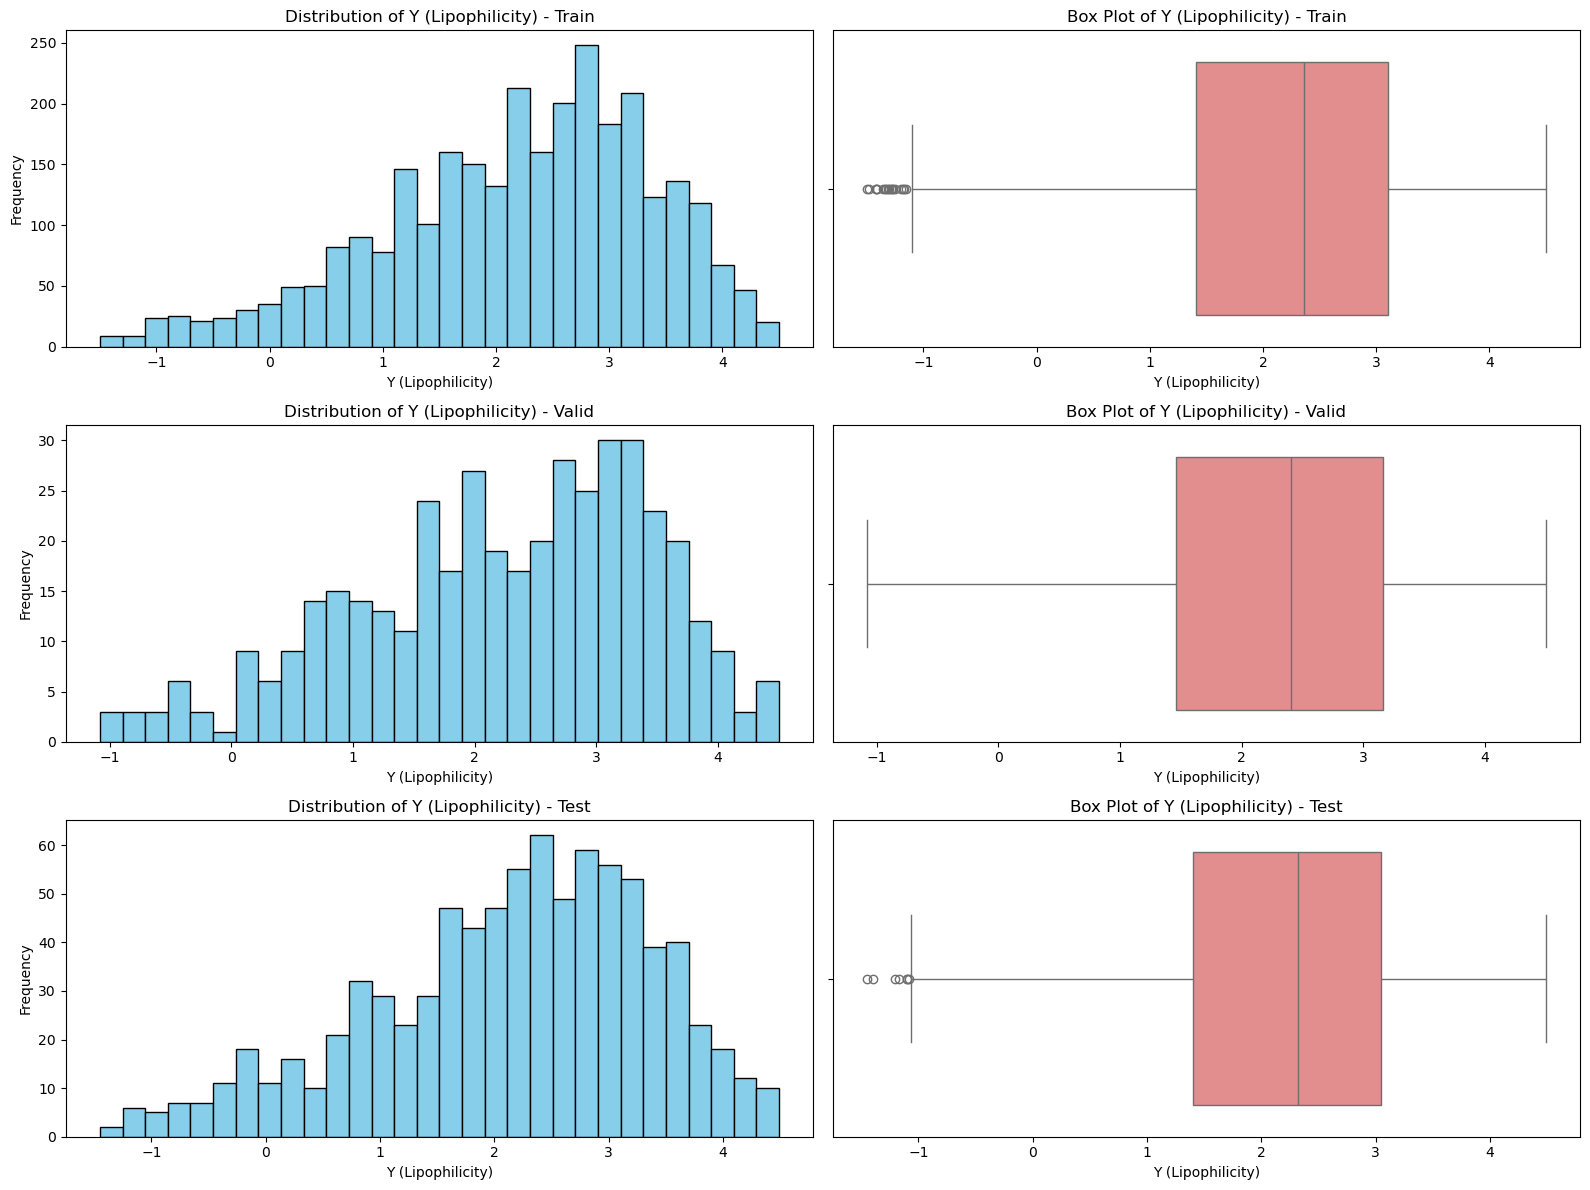

In [8]:
# distribution of column "Y" (target) for each set
figs, axs = plt.subplots(3, 2, figsize=(16, 12)) # distribution on left plot, box plot on right plot
axs[0, 0].hist(train['Y'], bins=30, color='skyblue', edgecolor='black')
axs[0, 0].set_title('Distribution of Y (Lipophilicity) - Train')
axs[0, 0].set_xlabel('Y (Lipophilicity)')
axs[0, 0].set_ylabel('Frequency')
sns.boxplot(x=train['Y'], ax=axs[0, 1], color='lightcoral')
axs[0, 1].set_title('Box Plot of Y (Lipophilicity) - Train')
axs[0, 1].set_xlabel('Y (Lipophilicity)')
axs[1, 0].hist(valid['Y'], bins=30, color='skyblue', edgecolor='black')
axs[1, 0].set_title('Distribution of Y (Lipophilicity) - Valid')
axs[1, 0].set_xlabel('Y (Lipophilicity)')
axs[1, 0].set_ylabel('Frequency')
sns.boxplot(x=valid['Y'], ax=axs[1, 1], color='lightcoral')
axs[1, 1].set_title('Box Plot of Y (Lipophilicity) - Valid')
axs[1, 1].set_xlabel('Y (Lipophilicity)')
axs[2, 0].hist(test['Y'], bins=30, color='skyblue', edgecolor='black')
axs[2, 0].set_title('Distribution of Y (Lipophilicity) - Test')
axs[2, 0].set_xlabel('Y (Lipophilicity)')
axs[2, 0].set_ylabel('Frequency')
sns.boxplot(x=test['Y'], ax=axs[2, 1], color='lightcoral')
axs[2, 1].set_title('Box Plot of Y (Lipophilicity) - Test')
axs[2, 1].set_xlabel('Y (Lipophilicity)')
plt.tight_layout()
plt.show()

Extremely satisfying to look at I would say.

So one thing that should caught our attention here is the outliers on train and test that are not in validation. Let's leave it untouched for our first iteration.

First Baseline regressor:

In [9]:
B_MODEL_LR = LinearRegression()

baseline_model = copy(B_MODEL_LR)
baseline_model.fit(train.drop(columns=['Drug_ID', 'Drug', 'Y', 'Mol', 'Canonical_SMILES']), train['Y'])
y_pred = baseline_model.predict(test.drop(columns=['Drug_ID', 'Drug', 'Y', 'Mol', 'Canonical_SMILES']))

r2 = r2_score(test['Y'], y_pred)
mae = mean_absolute_error(test['Y'], y_pred)
rmse = np.sqrt(mean_squared_error(test['Y'], y_pred))

print(f"\nBaseline test performance (Linear Regression on all descriptors): {len(train.drop(columns=['Drug_ID', 'Drug', 'Y', 'Mol', 'Canonical_SMILES']).columns)} descriptors")
print(f"R2   : {r2:.4f}")
print(f"MAE  : {mae:.4f}")
print(f"RMSE : {rmse:.4f}")


Baseline test performance (Linear Regression on all descriptors): 40 descriptors
R2   : 0.3312
MAE  : 0.7767
RMSE : 0.9941
